In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [7]:
digits = load_digits()
X, y = digits.data, digits.target
X.shape

(1797, 64)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [13]:
pca_full = PCA().fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
k95 = np.argmax(cum_var>=0.95) + 1
k95

np.int64(40)

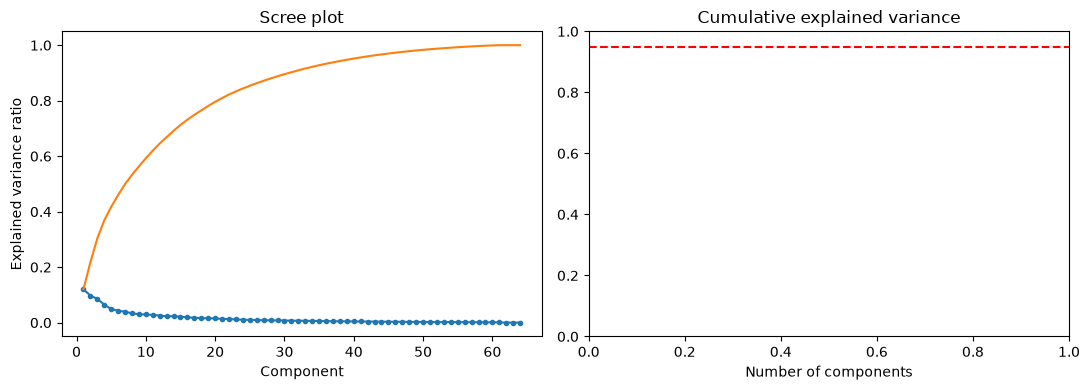

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(pca_full.explained_variance_ratio_)+ 1), pca_full.explained_variance_ratio_, marker='o', markersize=3)
ax[0].set(title='Scree plot', xlabel="Component", ylabel="Explained variance ratio")
ax[0].plot(range(1, len(cum_var)+1), cum_var)
ax[1].axhline(0.95, color='red', linestyle='--')
ax[1].set(title="Cumulative explained variance", xlabel="Number of components")
plt.tight_layout()

##### Reduce dimensions

In [15]:
pca = PCA(n_components=k95).fit(X_train_s)
X_train_p = pca.transform(X_train_s)
X_test_p = pca.transform(X_test_s)
X_train_s.shape, X_train_p.shape

((1437, 64), (1437, 40))

In [16]:
for n in [2, 5, 10, 20, 30, 40]:
    p=PCA(n_components=n).fit(X_train_s)
    rec = p.inverse_transform(p.transform(X_test_s))
    print(n, "components, reconstruction error: ",np.mean(X_test_s - rec)**2 )

2 components, reconstruction error:  0.00011652717448091509
5 components, reconstruction error:  0.00021669120416200696
10 components, reconstruction error:  3.0841047002405553e-05
20 components, reconstruction error:  9.555720495706233e-08
30 components, reconstruction error:  3.5254578305766285e-07
40 components, reconstruction error:  4.297780487392695e-08


In [17]:
X_test_rec = pca.inverse_transform(X_test_p)
X_test_rec_orig = scaler.inverse_transform(X_test_rec)

Text(0.0, 1.0, 'reconstructed')

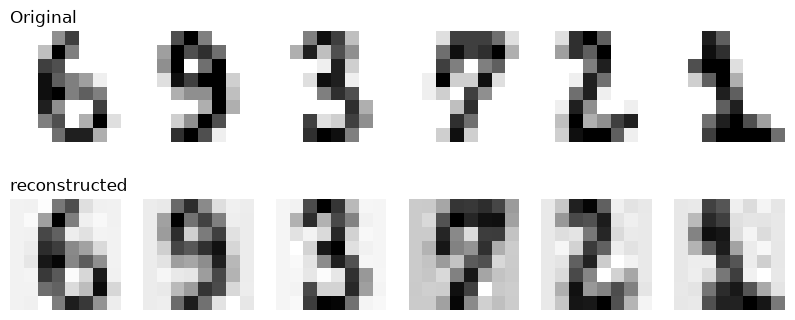

In [20]:
fig, ax = plt.subplots(2, 6, figsize=(10, 4))
for i in range(6):
    ax[0, i].imshow(X_test[i].reshape(8,8), cmap="gray_r"); ax[0, i].axis("off")
    ax[1, i].imshow(X_test_rec_orig[i].reshape(8,8), cmap="gray_r"); ax[1, i].axis("off")
ax[0, 0].set_title('Original', loc='left')
ax[1, 0].set_title("reconstructed", loc='left')

In [21]:
pca2 = PCA(n_components=2).fit(X_train_s)
Z_pca = pca2.transform(X_train_s)
print("Variance captured by the 2 components: ", pca2.explained_variance_ratio_.sum())

Variance captured by the 2 components:  0.21771103813204096


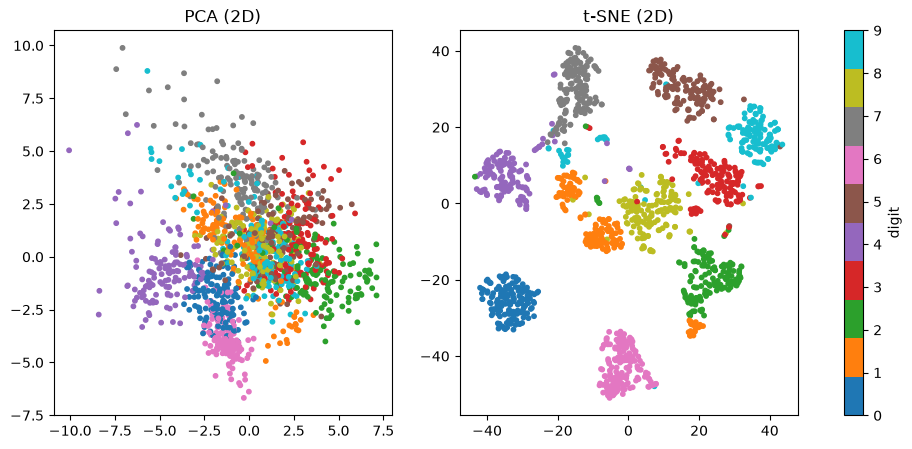

In [27]:
Z_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_train_s)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, Z, t in [(ax[0], Z_pca, "PCA (2D)"), (ax[1], Z_tsne, "t-SNE (2D)")]:
    sc= a.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="tab10", s=10)
    a.set_title(t)
plt.colorbar(sc, ax=ax, label="digit")


In [30]:
loadings = pca.components_[0]
top = np.argsort(np.abs(loadings))[::-1][:5]
print("Top contributing pixels to PC1", top)
print("Their loadings: ", loadings[top].round(3))

Top contributing pixels to PC1 [ 2 58  9 33 34]
Their loadings:  [ 0.287  0.281  0.245 -0.235 -0.231]


In [31]:
for name, data in [("Scaled, all 64 features", X_train_s), ("PCA-reduced", X_train_p)]:
    labels = KMeans(n_clusters=10, n_init=10, random_state=42).fit_predict(data)
    print(name, data.shape, "silhouette:", silhouette_score(data, labels))

Scaled, all 64 features (1437, 64) silhouette: 0.14725856577122165
PCA-reduced (1437, 40) silhouette: 0.16006443073502527
